In [1]:
import numpy as np  # Numerical calculations
import pandas as pd  # Work with power-flow results
import pandapower as pp  # Run AC power-flow calculations
import simbench as sb  # Load the benchmark network
import matplotlib.pyplot as plt  # Plot electrical results

SIMBENCH_CODE = "1-MVLV-urban-all-0-sw"  # Full urban MV/LV network

net = sb.get_simbench_net(SIMBENCH_CODE)  # Load a fresh network

print("Network loaded:", len(net.bus), "buses")

Network loaded: 10458 buses


In [2]:
load_abs = sb.get_absolute_profiles_from_relative_profiles(
    net,
    element="load",
    multiplying_column="p_mw",
    profile_suffix="_pload",
    time_as_index=True,
)  # Active-power demand in MW

renew_abs = sb.get_absolute_profiles_from_relative_profiles(
    net,
    element="sgen",
    multiplying_column="p_mw",
    time_as_index=True,
)  # Renewable generation in MW

In [3]:
print("Load profile shape :", load_abs.shape)
print("Renewable shape    :", renew_abs.shape)

print("\nLoad columns:")
print(load_abs.columns[:10])

print("\nRenewable columns:")
print(renew_abs.columns[:10])

Load profile shape : (35136, 11542)
Renewable shape    : (35136, 806)

Load columns:
RangeIndex(start=0, stop=10, step=1)

Renewable columns:
RangeIndex(start=0, stop=10, step=1)


In [4]:
total_load = load_abs.sum(axis=1)  # System demand at every timestep

peak_step = total_load.idxmax()  # Find maximum-demand timestep

print("Peak timestep:", peak_step)
print("Peak load    :", total_load.loc[peak_step], "MW")

Peak timestep: 09.12.2016 18:15
Peak load    : 20.625463089 MW


In [5]:
print(
    "Load mapping:",
    net.load.index.equals(load_abs.columns),
)

print(
    "Generator mapping:",
    net.sgen.index.equals(renew_abs.columns),
)

Load mapping: True
Generator mapping: True


In [6]:
load_q_abs = sb.get_absolute_profiles_from_relative_profiles(
    net,
    element="load",
    multiplying_column="q_mvar",
    profile_suffix="_qload",
    time_as_index=True,
)  # Reactive-power demand in MVAr

print("Reactive profile shape:", load_q_abs.shape)

Reactive profile shape: (35136, 11542)


In [7]:
net.load.loc[:, "p_mw"] = (
    load_abs.loc[peak_step].to_numpy()
)  # Apply active load at peak timestamp

net.load.loc[:, "q_mvar"] = (
    load_q_abs.loc[peak_step].to_numpy()
)  # Apply reactive load at peak timestamp

net.sgen.loc[:, "p_mw"] = (
    renew_abs.loc[peak_step].to_numpy()
)  # Apply renewable generation at same timestamp

In [8]:
print("--- APPLIED OPERATING POINT ---")

print(
    "Total load P:",
    net.load["p_mw"].sum(),
    "MW",
)

print(
    "Total renewable P:",
    net.sgen["p_mw"].sum(),
    "MW",
)

--- APPLIED OPERATING POINT ---
Total load P: 20.625463089 MW
Total renewable P: 1.7197674424 MW


In [9]:
import sys  # Show the Python used by this notebook
import numba  # Test whether Numba itself imports correctly

print("Python :", sys.executable)
print("Numba  :", numba.__version__)
print("Path   :", numba.__file__)

Python : c:\Users\sujit\AppData\Local\Programs\Python\Python311\python.exe
Numba  : 0.68.0
Path   : c:\Users\sujit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\__init__.py


In [10]:
import pandapower.pf.run_newton_raphson_pf as nr  # Inspect pandapower's Numba state

print("Pandapower sees Numba:", nr.numba_installed)

Pandapower sees Numba: True


In [11]:
pp.runpp(
    net,
    algorithm="nr",
    init="auto",
    
)  # Solve nonlinear AC power-flow equations

print("Power flow converged:", net.converged)

Power flow converged: True


In [16]:
print("\n--- PEAK-DEMAND POWER FLOW RESULTS ---")

print("Min bus voltage       :", net.res_bus["vm_pu"].min(), "pu")
print("Max bus voltage       :", net.res_bus["vm_pu"].max(), "pu")
print("Max line loading      :", net.res_line["loading_percent"].max(), "%")
print("Max transformer load  :", net.res_trafo["loading_percent"].max(), "%")

print("Grid import           :", net.res_ext_grid["p_mw"].sum(), "MW")
print("Line losses           :", net.res_line["pl_mw"].sum(), "MW")
print("Transformer losses    :", net.res_trafo["pl_mw"].sum(), "MW")

worst_bus = net.res_bus["vm_pu"].idxmin()  # Bus with minimum voltage

print("Worst bus index :", worst_bus)
print("Bus name        :", net.bus.loc[worst_bus, "name"])
print("Voltage level   :", net.bus.loc[worst_bus, "vn_kv"], "kV")
print("Voltage         :", net.res_bus.loc[worst_bus, "vm_pu"], "pu")

worst_line = net.res_line["loading_percent"].idxmax()  # Highest loaded line

print("Worst line index:", worst_line)
print("Line name       :", net.line.loc[worst_line, "name"])
print("From bus        :", net.line.loc[worst_line, "from_bus"])
print("To bus          :", net.line.loc[worst_line, "to_bus"])
print("Loading         :", net.res_line.loc[worst_line, "loading_percent"], "%")

worst_trafo = net.res_trafo["loading_percent"].idxmax()  # Highest loaded transformer

print("Transformer :", net.trafo.loc[worst_trafo, "name"])
print("HV voltage  :", net.trafo.loc[worst_trafo, "vn_hv_kv"], "kV")
print("LV voltage  :", net.trafo.loc[worst_trafo, "vn_lv_kv"], "kV")
print("Rating      :", net.trafo.loc[worst_trafo, "sn_mva"], "MVA")
print("Loading     :", net.res_trafo.loc[worst_trafo, "loading_percent"], "%")


--- PEAK-DEMAND POWER FLOW RESULTS ---
Min bus voltage       : 0.9946035936833804 pu
Max bus voltage       : 1.025 pu
Max line loading      : 32.20387423414259 %
Max transformer load  : 31.378085199883238 %
Grid import           : 19.359201740946098 MW
Line losses           : 0.13448361479863746 MW
Transformer losses    : 0.319022479548421 MW
Worst bus index : 5946
Bus name        : LV4.320 Bus 41
Voltage level   : 0.4 kV
Voltage         : 0.9946035936833804 pu
Worst line index: 10229
Line name       : MV3.101 Line 49
From bus        : 30949
To bus          : 31001
Loading         : 32.20387423414259 %
Transformer : MV3.101-LV3.306-Trafo
HV voltage  : 10.0 kV
LV voltage  : 0.4 kV
Rating      : 0.4 MVA
Loading     : 31.378085199883238 %


In [17]:
low_voltage = (
    net.res_bus["vm_pu"] < 0.95
).sum()  # Count buses below lower voltage limit

high_voltage = (
    net.res_bus["vm_pu"] > 1.05
).sum()  # Count buses above upper voltage limit

print("Low-voltage buses :", low_voltage)
print("High-voltage buses:", high_voltage)

Low-voltage buses : 0
High-voltage buses: 0


In [18]:
overloaded_lines = (
    net.res_line["loading_percent"] > 100
).sum()  # Count overloaded lines

overloaded_trafos = (
    net.res_trafo["loading_percent"] > 100
).sum()  # Count overloaded transformers

print("Overloaded lines       :", overloaded_lines)
print("Overloaded transformers:", overloaded_trafos)

Overloaded lines       : 0
Overloaded transformers: 0


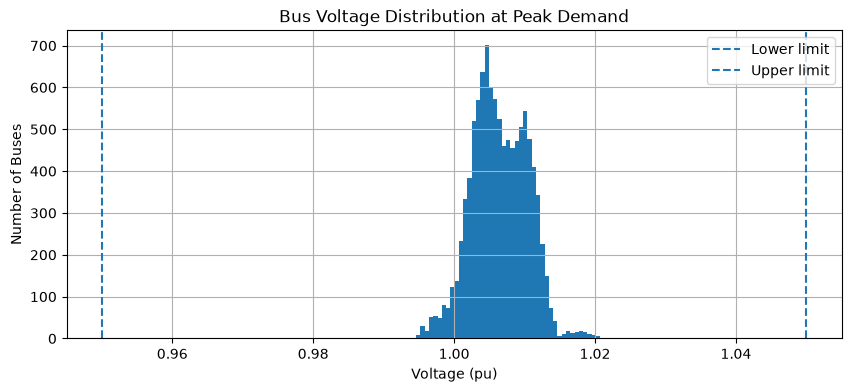

In [19]:
plt.figure(figsize=(10, 4))

plt.hist(
    net.res_bus["vm_pu"],
    bins=50
)  # Show voltage distribution across all buses

plt.axvline(0.95, linestyle="--", label="Lower limit")
plt.axvline(1.05, linestyle="--", label="Upper limit")

plt.xlabel("Voltage (pu)")
plt.ylabel("Number of Buses")
plt.title("Bus Voltage Distribution at Peak Demand")
plt.legend()
plt.grid(True)
plt.show()

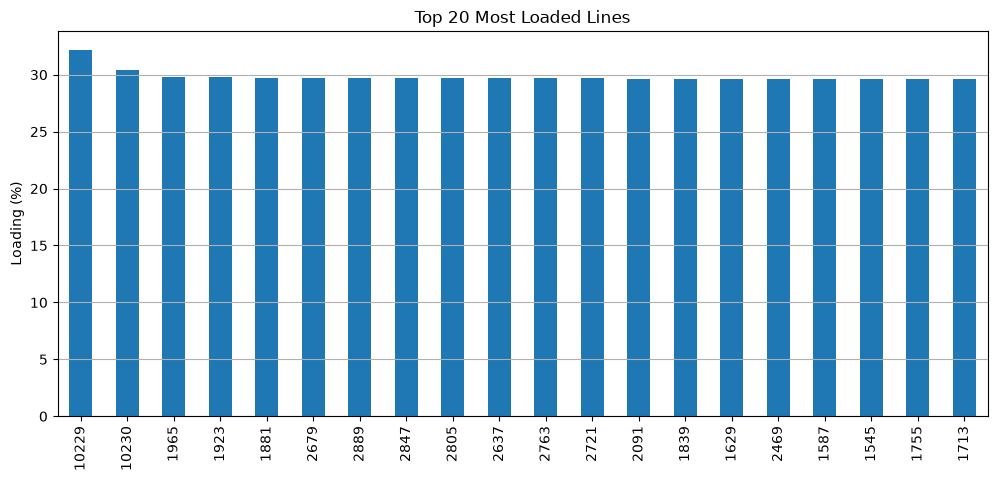

In [20]:
top_lines = (
    net.res_line["loading_percent"]
    .nlargest(20)
)  # Select twenty most loaded lines

plt.figure(figsize=(12, 5))
top_lines.plot(kind="bar")

plt.ylabel("Loading (%)")
plt.title("Top 20 Most Loaded Lines")
plt.grid(axis="y")
plt.show()

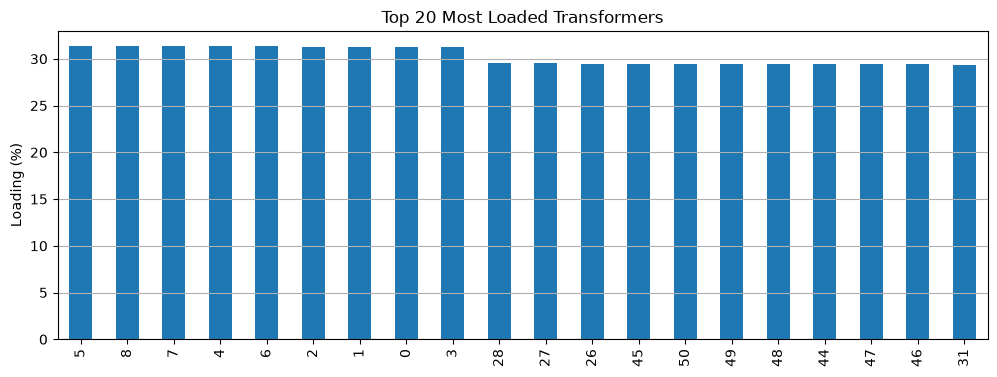

In [21]:
trafo_loading = (
    net.res_trafo["loading_percent"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 4))
trafo_loading.head(20).plot(kind="bar")

plt.ylabel("Loading (%)")
plt.title("Top 20 Most Loaded Transformers")
plt.grid(axis="y")
plt.show()

In [22]:
baseline_load_p = net.load["p_mw"].copy()  # Save baseline active load
baseline_load_q = net.load["q_mvar"].copy()  # Save baseline reactive load
baseline_sgen_p = net.sgen["p_mw"].copy()  # Save baseline renewable generation

In [23]:
DEMAND_SCALE = 1.50  # Simulate 50% demand growth

net.load["p_mw"] = baseline_load_p * DEMAND_SCALE  # Increase active demand
net.load["q_mvar"] = baseline_load_q * DEMAND_SCALE  # Preserve load power factor

pp.runpp(
    net,
    algorithm="nr",
    init="auto",
)  # Solve the stressed AC network

print("Converged:", net.converged)

Converged: True


In [25]:
print("--- 150% DEMAND SCENARIO ---")

print("Min voltage:",
      net.res_bus["vm_pu"].min(), "pu")

print("Max line loading:",
      net.res_line["loading_percent"].max(), "%")

print("Max transformer loading:",
      net.res_trafo["loading_percent"].max(), "%")

print("Grid import:",
      net.res_ext_grid["p_mw"].sum(), "MW")

print("Line losses:",
      net.res_line["pl_mw"].sum(), "MW")

print("Transformer losses:",
      net.res_trafo["pl_mw"].sum(), "MW")

--- 150% DEMAND SCENARIO ---
Min voltage: 0.9768578175901831 pu
Max line loading: 48.85803772383269 %
Max transformer loading: 47.521134635341454 %
Grid import: 29.940404829700316 MW
Line losses: 0.31257654061530366 MW
Transformer losses: 0.4094010979876834 MW


In [26]:
demand_scales = [1.0, 1.5, 2.0, 2.5, 3.0]  # Test increasing demand levels
results = []

for scale in demand_scales:
    net.load["p_mw"] = baseline_load_p * scale
    net.load["q_mvar"] = baseline_load_q * scale

    pp.runpp(net, algorithm="nr", init="auto")

    results.append({
        "Demand Scale": scale,
        "Min Voltage": net.res_bus["vm_pu"].min(),
        "Max Line Loading": net.res_line["loading_percent"].max(),
        "Max Trafo Loading": net.res_trafo["loading_percent"].max(),
        "Grid Import MW": net.res_ext_grid["p_mw"].sum(),
    })

In [27]:
stress_df = pd.DataFrame(results)  # Convert scenario results into a table

display(stress_df)

,Demand Scale,Min Voltage,Max Line Loading,Max Trafo Loading,Grid Import MW
0,1.0,0.994604,32.203874,31.378085,19.359202
1,1.5,0.976858,48.858038,47.521135,29.940405
2,2.0,0.957583,66.051567,64.171541,40.648223
3,2.5,0.936540,83.893531,81.433021,51.495754
4,3.0,0.913413,102.528152,99.440847,62.500067


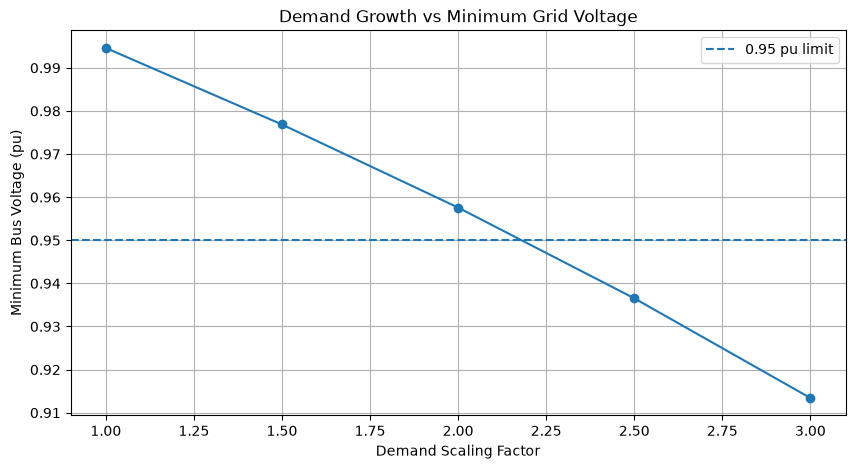

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    stress_df["Demand Scale"],
    stress_df["Min Voltage"],
    marker="o"
)  # Show voltage degradation as demand increases

plt.axhline(0.95, linestyle="--", label="0.95 pu limit")
plt.xlabel("Demand Scaling Factor")
plt.ylabel("Minimum Bus Voltage (pu)")
plt.title("Demand Growth vs Minimum Grid Voltage")
plt.legend()
plt.grid(True)
plt.show()

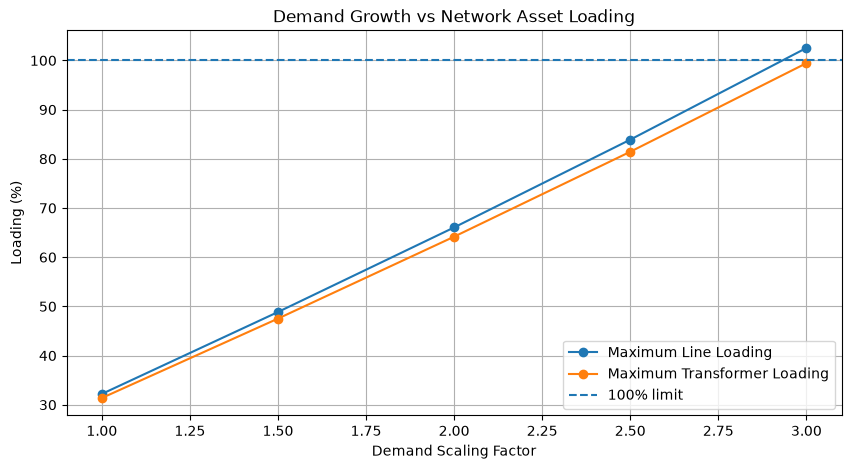

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    stress_df["Demand Scale"],
    stress_df["Max Line Loading"],
    marker="o",
    label="Maximum Line Loading"
)

plt.plot(
    stress_df["Demand Scale"],
    stress_df["Max Trafo Loading"],
    marker="o",
    label="Maximum Transformer Loading"
)

plt.axhline(100, linestyle="--", label="100% limit")
plt.xlabel("Demand Scaling Factor")
plt.ylabel("Loading (%)")
plt.title("Demand Growth vs Network Asset Loading")
plt.legend()
plt.grid(True)
plt.show()

## Reusable Digital Twin Engine

In [30]:
import pandapower as pp  # Solve AC power flow
import simbench as sb  # Load the benchmark network

SIMBENCH_CODE = "1-MVLV-urban-all-0-sw"  # Full urban MV/LV grid

grid = sb.get_simbench_net(
    SIMBENCH_CODE
)  # Keep one clean network for reusable simulations

print("Buses:", len(grid.bus))
print("Loads:", len(grid.load))
print("Generators:", len(grid.sgen))

Buses: 10458
Loads: 11542
Generators: 806


In [32]:
load_p = sb.get_absolute_profiles_from_relative_profiles(
    grid, element="load",
    multiplying_column="p_mw",
    profile_suffix="_pload",
    time_as_index=True,
)  # Active demand at every 15-minute timestamp

renew_p = sb.get_absolute_profiles_from_relative_profiles(
    grid, element="sgen",
    multiplying_column="p_mw",
    time_as_index=True,
)  # Renewable generation at every timestamp

load_q = sb.get_absolute_profiles_from_relative_profiles(
    grid, element="load",
    multiplying_column="q_mvar",
    profile_suffix="_qload",
    time_as_index=True,
)  # Reactive demand required for AC power flow

print(load_p.shape)
print(load_q.shape)
print(renew_p.shape)

(35136, 11542)
(35136, 11542)
(35136, 806)


In [33]:
def apply_grid_state(timestamp, load_scale=1.0, renewable_scale=1.0):
    grid.load["p_mw"] = (
        load_p.loc[timestamp].to_numpy() * load_scale
    )  # Apply timestamp-specific active demand

    grid.load["q_mvar"] = (
        load_q.loc[timestamp].to_numpy() * load_scale
    )  # Scale reactive demand consistently

    grid.sgen["p_mw"] = (
        renew_p.loc[timestamp].to_numpy() * renewable_scale
    )  # Apply renewable operating condition

In [57]:
def solve_grid():
    pp.runpp(grid, algorithm="nr", init="auto")  # Solve the complete AC network

    min_bus = grid.res_bus["vm_pu"].idxmin()  # Lowest-voltage bus
    max_bus = grid.res_bus["vm_pu"].idxmax()  # Highest-voltage bus

    worst_line = grid.res_line["loading_percent"].idxmax()
    worst_trafo = grid.res_trafo["loading_percent"].idxmax()
    line_loss = grid.res_line["pl_mw"].sum()  # Total active line losses
    trafo_loss = grid.res_trafo["pl_mw"].sum()  # Total transformer losses

    return {
        "v_min_pu": grid.res_bus.loc[min_bus, "vm_pu"],
        "v_min_bus": grid.bus.loc[min_bus, "name"],

        "v_max_pu": grid.res_bus.loc[max_bus, "vm_pu"],
        "v_max_bus": grid.bus.loc[max_bus, "name"],
        "worst_bus": grid.bus.loc[worst_bus, "name"],
        "max_line_pct": grid.res_line.loc[worst_line, "loading_percent"],
        "worst_line": grid.line.loc[worst_line, "name"],
        "max_trafo_pct": grid.res_trafo.loc[worst_trafo, "loading_percent"],
        "worst_trafo": grid.trafo.loc[worst_trafo, "name"],
        "grid_import_mw": grid.res_ext_grid["p_mw"].sum(),
    }

In [37]:
test_time = "09.12.2016 18:15"

apply_grid_state(
    test_time,
    load_scale=1.0,
    renewable_scale=1.0,
)

results = solve_grid()

for key, value in results.items():
    print(f"{key}: {value}")

v_min_pu: 0.9946035936833804
v_max_pu: 1.025
worst_bus: LV4.320 Bus 41
max_line_pct: 32.20387423414259
worst_line: MV3.101 Line 49
max_trafo_pct: 31.378085199883238
worst_trafo: MV3.101-LV3.306-Trafo
grid_import_mw: 19.359201740946098


In [83]:
import numpy as np
import pandapower as pp
import pandapower.topology as top
import simbench as sb

SIMBENCH_CODE = "1-MVLV-urban-all-0-sw"

grid = sb.get_simbench_net(SIMBENCH_CODE)

BASE_LINE_STATUS = grid.line["in_service"].copy()
BASE_TRAFO_STATUS = grid.trafo["in_service"].copy()

print("Buses:", len(grid.bus))
print("Loads:", len(grid.load))
print("Generators:", len(grid.sgen))

Buses: 10458
Loads: 11542
Generators: 806


In [84]:
load_p = sb.get_absolute_profiles_from_relative_profiles(
    grid, element="load", multiplying_column="p_mw",
    profile_suffix="_pload", time_as_index=True,
)

load_q = sb.get_absolute_profiles_from_relative_profiles(
    grid, element="load", multiplying_column="q_mvar",
    profile_suffix="_qload", time_as_index=True,
)

renew_p = sb.get_absolute_profiles_from_relative_profiles(
    grid, element="sgen", multiplying_column="p_mw",
    time_as_index=True,
)

print(load_p.shape, load_q.shape, renew_p.shape)

(35136, 11542) (35136, 11542) (35136, 806)


In [85]:
def apply_grid_state(timestamp, load_scale=1.0, renewable_scale=1.0):
    grid.load["p_mw"] = (
        load_p.loc[timestamp].to_numpy() * load_scale
    )

    grid.load["q_mvar"] = (
        load_q.loc[timestamp].to_numpy() * load_scale
    )

    grid.sgen["p_mw"] = (
        renew_p.loc[timestamp].to_numpy() * renewable_scale
    )

In [86]:
def clear_ev_loads():
    ev_mask = grid.load["type"].eq("EV")
    grid.load.drop(
        index=grid.load.index[ev_mask],
        inplace=True,
    )

def apply_ev_loads(ev_bus_loads):
    for bus, p_mw in ev_bus_loads.items():
        pp.create_load(
            grid, bus=int(bus), p_mw=float(p_mw),
            q_mvar=0.0, name=f"EV_Load_Bus_{bus}", type="EV",
        )

In [87]:
def clear_batteries():
    grid.storage.drop(
        index=grid.storage.index,
        inplace=True,
    )

def apply_batteries(battery_bus_power):
    for bus, p_mw in battery_bus_power.items():
        pp.create_storage(
            grid, bus=int(bus), p_mw=float(p_mw),
            max_e_mwh=1.0, soc_percent=50.0,
            q_mvar=0.0, name=f"Battery_Bus_{bus}",
        )

In [88]:
def reset_contingencies():
    grid.line["in_service"] = BASE_LINE_STATUS.copy()
    grid.trafo["in_service"] = BASE_TRAFO_STATUS.copy()

def apply_contingencies(outaged_lines=None, outaged_trafos=None):
    for idx in outaged_lines or []:
        if idx not in grid.line.index:
            raise ValueError(f"Invalid line index: {idx}")
        grid.line.at[idx, "in_service"] = False

    for idx in outaged_trafos or []:
        if idx not in grid.trafo.index:
            raise ValueError(f"Invalid transformer index: {idx}")
        grid.trafo.at[idx, "in_service"] = False

In [114]:
def solve_grid():
    try:
        pp.runpp(grid, algorithm="nr", init="auto")  # Attempt AC power flow
    except pp.LoadflowNotConverged:
        return {
            "converged": False,
            "v_min_pu": np.nan,
            "v_min_bus": None,
            "v_max_pu": np.nan,
            "v_max_bus": None,
        }

    min_bus = grid.res_bus["vm_pu"].idxmin()  # Lowest-voltage bus
    max_bus = grid.res_bus["vm_pu"].idxmax()  # Highest-voltage bus
    worst_line = grid.res_line["loading_percent"].idxmax()
    worst_trafo = grid.res_trafo["loading_percent"].idxmax()
    return {
        "converged": True,
        "v_min_pu": grid.res_bus.loc[min_bus, "vm_pu"],
        "v_min_bus": grid.bus.loc[min_bus, "name"],
        "v_max_pu": grid.res_bus.loc[max_bus, "vm_pu"],
        "v_max_bus": grid.bus.loc[max_bus, "name"],
        "max_line_pct": grid.res_line.loc[worst_line, "loading_percent"],
        "worst_line": grid.line.loc[worst_line, "name"],
        "max_trafo_pct": grid.res_trafo.loc[worst_trafo, "loading_percent"],
        "worst_trafo": grid.trafo.loc[worst_trafo, "name"],
        "grid_import_mw": grid.res_ext_grid["p_mw"].sum(),
    }

In [115]:
def get_grid_metrics():
    line_loss = grid.res_line["pl_mw"].sum()
    trafo_loss = grid.res_trafo["pl_mw"].sum()

    unsupplied = top.unsupplied_buses(grid)
    load_unsupplied = grid.load["bus"].isin(unsupplied)
    sgen_unsupplied = grid.sgen["bus"].isin(unsupplied)

    total_load = grid.load["p_mw"].sum()
    lost_load = grid.load.loc[load_unsupplied, "p_mw"].sum()
    lost_generation = grid.sgen.loc[sgen_unsupplied, "p_mw"].sum()

    voltage_bad = (
        (grid.res_bus["vm_pu"] < 0.95)
        | (grid.res_bus["vm_pu"] > 1.05)
    )
    return {
        "unsupplied_buses": len(unsupplied),
        "configured_load_mw": total_load,
        "unsupplied_load_mw": lost_load,
        "supplied_load_mw": total_load - lost_load,
        "renewable_mw": grid.sgen["p_mw"].sum(),
        "unsupplied_generation_mw": lost_generation,
        "line_losses_mw": line_loss,
        "trafo_losses_mw": trafo_loss,
        "total_losses_mw": line_loss + trafo_loss,
        "voltage_violations": int(voltage_bad.sum()),
        "line_overloads": int(
            (grid.res_line["loading_percent"] > 100).sum()
        ),
        "trafo_overloads": int(
            (grid.res_trafo["loading_percent"] > 100).sum()
        ),
    }

In [116]:
def run_grid(timestamp, load_scale=1.0, renewable_scale=1.0,
             ev_bus_loads=None, battery_bus_power=None,
             outaged_lines=None, outaged_trafos=None):

    clear_ev_loads()
    clear_batteries()
    reset_contingencies()

    apply_grid_state(
        timestamp, load_scale, renewable_scale
    )

    apply_contingencies(
        outaged_lines, outaged_trafos
    )
    if ev_bus_loads:
        apply_ev_loads(ev_bus_loads)

    if battery_bus_power:
        apply_batteries(battery_bus_power)

    electrical = solve_grid()  # Run AC power flow

    if electrical["converged"]:
        metrics = get_grid_metrics()  # Read results only after a valid solution
    else:
        metrics = {
            "power_flow_failed": True
        }  # Preserve the failed scenario without crashing

    return {
        "timestamp": timestamp,
        "load_scale": load_scale,
        "renewable_scale": renewable_scale,
        "ev_load_mw": (
            sum(ev_bus_loads.values())
            if ev_bus_loads else 0.0
        ),
        "battery_power_mw": (
            sum(battery_bus_power.values())
            if battery_bus_power else 0.0
        ),
        "outaged_lines": outaged_lines or [],
        "outaged_trafos": outaged_trafos or [],
        **electrical,
        **metrics,
    }

In [117]:
baseline = run_grid(
    "09.12.2016 18:15",
    load_scale=1.0,
    renewable_scale=1.0,
)

for key, value in baseline.items():
    print(f"{key}: {value}")

timestamp: 09.12.2016 18:15
load_scale: 1.0
renewable_scale: 1.0
ev_load_mw: 0.0
battery_power_mw: 0.0
outaged_lines: []
outaged_trafos: []
converged: True
v_min_pu: 0.9946035936833804
v_min_bus: LV4.320 Bus 41
v_max_pu: 1.025
v_max_bus: HV1 Bus 25
max_line_pct: 32.20387423414259
worst_line: MV3.101 Line 49
max_trafo_pct: 31.378085199883238
worst_trafo: MV3.101-LV3.306-Trafo
grid_import_mw: 19.359201740946098
unsupplied_buses: 0
configured_load_mw: 20.625463089
unsupplied_load_mw: 0.0
supplied_load_mw: 20.625463089
renewable_mw: 1.7197674424
unsupplied_generation_mw: 0.0
line_losses_mw: 0.13448361479863746
trafo_losses_mw: 0.319022479548421
total_losses_mw: 0.45350609434705846
voltage_violations: 0
line_overloads: 0
trafo_overloads: 0


In [118]:
ev_test = {
    5946: 0.50,
}

with_ev = run_grid(
    "09.12.2016 18:15",
    ev_bus_loads=ev_test,
)

print(with_ev)

{'timestamp': '09.12.2016 18:15', 'load_scale': 1.0, 'renewable_scale': 1.0, 'ev_load_mw': 0.5, 'battery_power_mw': 0.0, 'outaged_lines': [], 'outaged_trafos': [], 'converged': True, 'v_min_pu': np.float64(0.7818217781842025), 'v_min_bus': 'LV4.320 Bus 41', 'v_max_pu': np.float64(1.025), 'v_max_bus': 'HV1 Bus 25', 'max_line_pct': np.float64(375.4281009378962), 'worst_line': 'LV4.320 Line 34', 'max_trafo_pct': np.float64(192.16382842911258), 'worst_trafo': 'MV3.101-LV4.320-Trafo 1', 'grid_import_mw': np.float64(20.011562006762713), 'unsupplied_buses': 0, 'configured_load_mw': np.float64(21.125463089), 'unsupplied_load_mw': np.float64(0.0), 'supplied_load_mw': np.float64(21.125463089), 'renewable_mw': np.float64(1.7197674424), 'unsupplied_generation_mw': np.float64(0.0), 'line_losses_mw': np.float64(0.2689953252162529), 'trafo_losses_mw': np.float64(0.33687103494742887), 'total_losses_mw': np.float64(0.6058663601636818), 'voltage_violations': 9, 'line_overloads': 6, 'trafo_overloads': 1}

In [119]:
lv_buses = grid.bus[
    (grid.bus["vn_kv"] == 0.4)
    & grid.bus["in_service"]
].index

positions = np.linspace(
    0, len(lv_buses) - 1, 10, dtype=int
)

test_ev_buses = lv_buses[positions]
distributed_ev = {
    int(bus): 0.05 for bus in test_ev_buses
}

In [120]:
distributed_result = run_grid(
    "09.12.2016 18:15",
    ev_bus_loads=distributed_ev,
)

print(distributed_result)

{'timestamp': '09.12.2016 18:15', 'load_scale': 1.0, 'renewable_scale': 1.0, 'ev_load_mw': 0.49999999999999994, 'battery_power_mw': 0.0, 'outaged_lines': [], 'outaged_trafos': [], 'converged': True, 'v_min_pu': np.float64(0.9856457238427053), 'v_min_bus': 'LV5.326 Bus 94', 'v_max_pu': np.float64(1.025), 'v_max_bus': 'HV1 Bus 25', 'max_line_pct': np.float64(56.65476225256801), 'worst_line': 'LV4.327 Line 33', 'max_trafo_pct': np.float64(43.78931582467359), 'worst_trafo': 'MV3.101-LV3.309-Trafo', 'grid_import_mw': np.float64(19.873402332174432), 'unsupplied_buses': 0, 'configured_load_mw': np.float64(21.125463089), 'unsupplied_load_mw': np.float64(0.0), 'supplied_load_mw': np.float64(21.125463089), 'renewable_mw': np.float64(1.7197674424), 'unsupplied_generation_mw': np.float64(0.0), 'line_losses_mw': np.float64(0.14461058776290905), 'trafo_losses_mw': np.float64(0.32309609781246845), 'total_losses_mw': np.float64(0.46770668557537753), 'voltage_violations': 0, 'line_overloads': 0, 'trafo

In [121]:
battery_discharge_50 = {
    int(test_ev_buses[0]): -0.05
}

battery_result = run_grid(
    "09.12.2016 18:15",
    battery_bus_power=battery_discharge_50,
)

print(battery_result)

{'timestamp': '09.12.2016 18:15', 'load_scale': 1.0, 'renewable_scale': 1.0, 'ev_load_mw': 0.0, 'battery_power_mw': -0.05, 'outaged_lines': [], 'outaged_trafos': [], 'converged': True, 'v_min_pu': np.float64(0.9946035936832447), 'v_min_bus': 'LV4.320 Bus 41', 'v_max_pu': np.float64(1.025), 'v_max_bus': 'HV1 Bus 25', 'max_line_pct': np.float64(32.20387423424171), 'worst_line': 'MV3.101 Line 49', 'max_trafo_pct': np.float64(31.37808519987249), 'worst_trafo': 'MV3.101-LV3.306-Trafo', 'grid_import_mw': np.float64(19.30890822167379), 'unsupplied_buses': 0, 'configured_load_mw': np.float64(20.625463089), 'unsupplied_load_mw': np.float64(0.0), 'supplied_load_mw': np.float64(20.625463089), 'renewable_mw': np.float64(1.7197674424), 'unsupplied_generation_mw': np.float64(0.0), 'line_losses_mw': np.float64(0.13451593719101748), 'trafo_losses_mw': np.float64(0.31869663788364955), 'total_losses_mw': np.float64(0.45321257507466706), 'voltage_violations': 0, 'line_overloads': 0, 'trafo_overloads': 0}

In [122]:
battery_charge_50 = {
    int(test_ev_buses[0]): 0.05
}

battery_charge_result = run_grid(
    "09.12.2016 18:15",
    battery_bus_power=battery_charge_50,
)

print(battery_charge_result)

{'timestamp': '09.12.2016 18:15', 'load_scale': 1.0, 'renewable_scale': 1.0, 'ev_load_mw': 0.0, 'battery_power_mw': 0.05, 'outaged_lines': [], 'outaged_trafos': [], 'converged': True, 'v_min_pu': np.float64(0.9946035936833317), 'v_min_bus': 'LV4.320 Bus 41', 'v_max_pu': np.float64(1.025), 'v_max_bus': 'HV1 Bus 25', 'max_line_pct': np.float64(32.75386841668604), 'worst_line': 'LV3.301 Line 124', 'max_trafo_pct': np.float64(43.70696963335872), 'worst_trafo': 'MV3.101-LV3.301-Trafo', 'grid_import_mw': np.float64(19.41037488587121), 'unsupplied_buses': 0, 'configured_load_mw': np.float64(20.625463089), 'unsupplied_load_mw': np.float64(0.0), 'supplied_load_mw': np.float64(20.625463089), 'renewable_mw': np.float64(1.7197674424), 'unsupplied_generation_mw': np.float64(0.0), 'line_losses_mw': np.float64(0.13517500120053755), 'trafo_losses_mw': np.float64(0.3195042380716221), 'total_losses_mw': np.float64(0.45467923927215964), 'voltage_violations': 0, 'line_overloads': 0, 'trafo_overloads': 0}


In [123]:
battery_discharge_200 = {
    5946: -0.20
}

battery_stress = run_grid(
    "09.12.2016 18:15",
    battery_bus_power=battery_discharge_200,
)

print(battery_stress)

{'timestamp': '09.12.2016 18:15', 'load_scale': 1.0, 'renewable_scale': 1.0, 'ev_load_mw': 0.0, 'battery_power_mw': -0.2, 'outaged_lines': [], 'outaged_trafos': [], 'converged': True, 'v_min_pu': np.float64(0.9955042204520326), 'v_min_bus': 'LV4.319 Bus 41', 'v_max_pu': np.float64(1.0522272464549236), 'v_max_bus': 'LV4.320 Bus 41', 'max_line_pct': np.float64(97.87156765622471), 'worst_line': 'LV4.320 Line 39', 'max_trafo_pct': np.float64(31.377134530919587), 'worst_trafo': 'MV3.101-LV3.306-Trafo', 'grid_import_mw': np.float64(19.162797945238076), 'unsupplied_buses': 0, 'configured_load_mw': np.float64(20.625463089), 'unsupplied_load_mw': np.float64(0.0), 'supplied_load_mw': np.float64(20.625463089), 'renewable_mw': np.float64(1.7197674424), 'unsupplied_generation_mw': np.float64(0.0), 'line_losses_mw': np.float64(0.13849177776585503), 'trafo_losses_mw': np.float64(0.3186105208731055), 'total_losses_mw': np.float64(0.4571022986389605), 'voltage_violations': 1, 'line_overloads': 0, 'traf

In [124]:
line_outage = run_grid(
    "09.12.2016 18:15",
    load_scale=1.0,
    renewable_scale=1.0,
    outaged_lines=[10229],
)

print(line_outage)

{'timestamp': '09.12.2016 18:15', 'load_scale': 1.0, 'renewable_scale': 1.0, 'ev_load_mw': 0.0, 'battery_power_mw': 0.0, 'outaged_lines': [10229], 'outaged_trafos': [], 'converged': True, 'v_min_pu': np.float64(0.9998960565568435), 'v_min_bus': 'LV5.344 Bus 94', 'v_max_pu': np.float64(1.025), 'v_max_bus': 'HV1 Bus 25', 'max_line_pct': np.float64(29.648945889386653), 'worst_line': 'LV4.337 Line 33', 'max_trafo_pct': np.float64(31.324982257001455), 'worst_trafo': 'MV3.101-LV3.306-Trafo', 'grid_import_mw': np.float64(16.354250340592543), 'unsupplied_buses': 1247, 'configured_load_mw': np.float64(20.625463089), 'unsupplied_load_mw': np.float64(2.939282967), 'supplied_load_mw': np.float64(17.686180122), 'renewable_mw': np.float64(1.7197674424), 'unsupplied_generation_mw': np.float64(0.0), 'line_losses_mw': np.float64(0.1081976497148343), 'trafo_losses_mw': np.float64(0.27964001127841315), 'total_losses_mw': np.float64(0.38783766099324746), 'voltage_violations': 0, 'line_overloads': 0, 'traf

In [125]:
normal_test = run_grid(
    "09.12.2016 18:15"
)

print("Converged:", normal_test["converged"])
print("Vmin:", normal_test["v_min_pu"])
print("Max line:", normal_test["max_line_pct"])

Converged: True
Vmin: 0.9946035936833804
Max line: 32.20387423414259


In [126]:
stress_test = run_grid(
    "09.12.2016 18:15",
    load_scale=4.0,
    renewable_scale=0.2,
)

print(stress_test)

{'timestamp': '09.12.2016 18:15', 'load_scale': 4.0, 'renewable_scale': 0.2, 'ev_load_mw': 0.0, 'battery_power_mw': 0.0, 'outaged_lines': [], 'outaged_trafos': [], 'converged': True, 'v_min_pu': np.float64(0.8578402234003328), 'v_min_bus': 'LV4.320 Bus 41', 'v_max_pu': np.float64(1.025), 'v_max_bus': 'HV1 Bus 25', 'max_line_pct': np.float64(143.21290039447697), 'worst_line': 'MV3.101 Line 49', 'max_trafo_pct': np.float64(138.66422085692892), 'worst_trafo': 'MV3.101-LV3.306-Trafo', 'grid_import_mw': np.float64(86.50693790644854), 'unsupplied_buses': 0, 'configured_load_mw': np.float64(82.501852356), 'unsupplied_load_mw': np.float64(0.0), 'supplied_load_mw': np.float64(82.501852356), 'renewable_mw': np.float64(0.34395348848), 'unsupplied_generation_mw': np.float64(0.0), 'line_losses_mw': np.float64(2.731839748766551), 'trafo_losses_mw': np.float64(1.6171992901657017), 'total_losses_mw': np.float64(4.349039038932252), 'voltage_violations': 9362, 'line_overloads': 454, 'trafo_overloads': 1